# EDA, Clean และ Data Prep: ความชื้นและฝนรายวัน (2020–2025)

ลำดับการทำงาน: โหลดข้อมูล → EDA/กราฟก่อน Clean → Clean → Data Prep → EDA/กราฟหลังเตรียมข้อมูล → Save CSV

## 1. โหลดข้อมูลต้นฉบับ

อ่านไฟล์ `NST_district_daily_humidity_2020_2025.csv` จาก `raw_data` เลือกเฉพาะปี 2020–2025 แล้วเก็บข้อมูลก่อน Clean ไว้ใน `raw_data` สำหรับ EDA รอบแรก

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

filename = 'NST_district_daily_humidity_2020_2025.csv'
root = next((path for path in [Path.cwd(), *Path.cwd().parents]
             if (path / 'raw_data' / filename).is_file()), None)
if root is None:
    raise FileNotFoundError(f'ไม่พบไฟล์ raw_data/{filename}')

source_path = root / 'raw_data' / filename
years = [2020, 2021, 2022, 2023, 2024, 2025]
all_data = pd.read_csv(source_path)
date_year = pd.to_datetime(all_data['date'], errors='coerce').dt.year
raw_data = all_data.loc[date_year.isin(years)].copy()
print(f'ไฟล์ต้นทาง: {source_path}')
print(f'ข้อมูลในไฟล์ทั้งหมด: {len(all_data):,} แถว | หลังเลือกปี {years}: {len(raw_data):,} แถว')
print(f'จำนวนอำเภอ: {raw_data["district"].nunique()} | ช่วงวันที่: {raw_data["date"].min()} ถึง {raw_data["date"].max()}')
print(f'ช่วงวันที่: {raw_data["date"].min()} ถึง {raw_data["date"].max()}')
display(raw_data.head())

ไฟล์ต้นทาง: c:\Users\sitti\OneDrive\Desktop\nahh ahhh ver nine edit - Copy\nahh ahhh\raw_data\NST_district_daily_humidity_2020_2025.csv
ข้อมูลในไฟล์ทั้งหมด: 39,456 แถว | หลังเลือกปี [2020, 2021, 2022, 2023, 2024, 2025]: 39,456 แถว
จำนวนอำเภอ: 18 | ช่วงวันที่: 2020-01-01 ถึง 2025-12-31
ช่วงวันที่: 2020-01-01 ถึง 2025-12-31


,province,district,district_code,date,rh_pct,q_gkg,dewpoint_c,temp_c,rain_mm,heavy
0,นครศรีธรรมราช,Bang Khan,26738,2020-01-01,76.31,15.95,21.44,25.93,0.0,0
1,นครศรีธรรมราช,Bang Khan,26738,2020-01-02,77.48,16.28,21.77,26.02,0.0,0
2,นครศรีธรรมราช,Bang Khan,26738,2020-01-03,81.57,16.95,22.41,25.80,0.0,0
3,นครศรีธรรมราช,Bang Khan,26738,2020-01-04,75.65,16.31,21.76,26.41,0.0,0
4,นครศรีธรรมราช,Bang Khan,26738,2020-01-05,75.34,15.82,21.27,25.98,0.0,0


## 2. EDA ก่อน Clean: ตรวจข้อมูลและแสดงกราฟ

สำรวจ `raw_data` ก่อนทำความสะอาด กราฟแสดงค่าเฉลี่ยฝนและความชื้นรายเดือนจากข้อมูลทุกอำเภอ โดยใช้ตารางชั่วคราวสำหรับวาดกราฟ ไม่แก้ `raw_data`

ขนาดข้อมูล: (39456, 10)
ค่าว่างต่อคอลัมน์:
 province            0
district            0
district_code       0
date                0
rh_pct           2192
q_gkg            2192
dewpoint_c       2192
temp_c           2192
rain_mm             0
heavy               0
แถวซ้ำทั้งหมด: 0
แถวซ้ำตามอำเภอและวันที่: 0


,rh_pct,q_gkg,dewpoint_c,temp_c,rain_mm,heavy
count,37264.00,37264.00,37264.00,37264.00,39456.00,39456.00
mean,82.76,17.68,22.94,26.19,7.53,0.04
std,7.58,1.21,1.21,1.50,13.04,0.20
min,48.77,10.96,14.95,21.52,0.00,0.00
25%,78.60,17.09,22.34,25.15,0.00,0.00
50%,83.54,17.94,23.21,26.10,1.84,0.00
75%,88.07,18.48,23.77,27.14,10.29,0.00
max,99.35,21.77,26.61,32.11,213.42,1.00


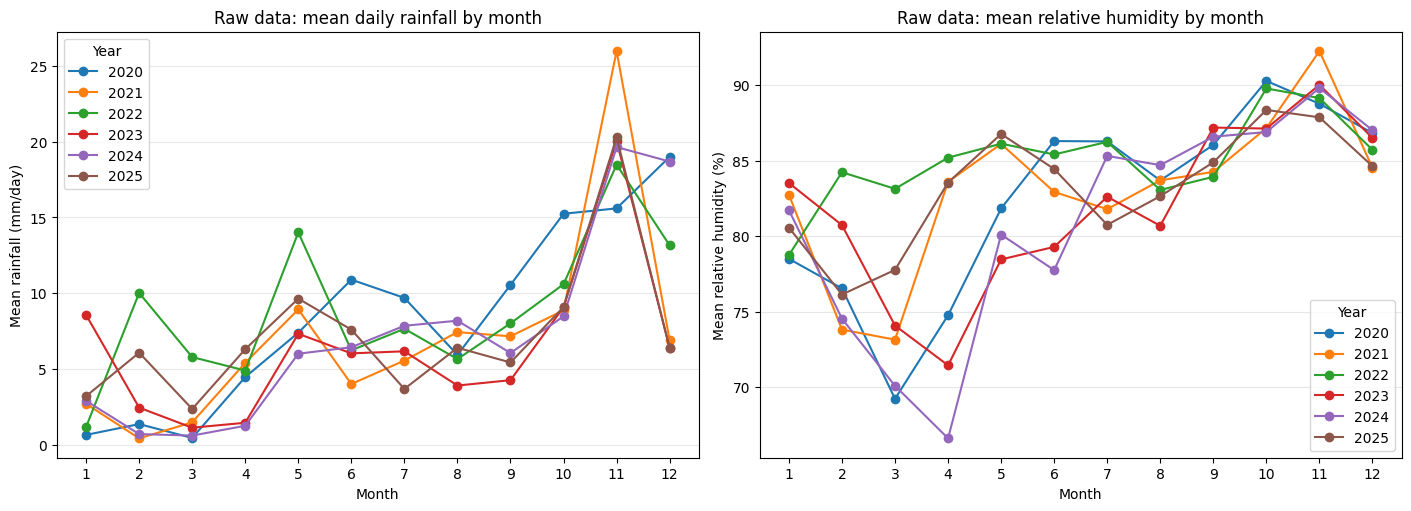

,year_for_eda,month_for_eda,mean_rain_mm,mean_rh_pct
0,2020,1,0.64,78.50
1,2020,2,1.35,76.54
2,2020,3,0.44,69.23
3,2020,4,4.46,74.76
4,2020,5,7.39,81.84
5,2020,6,10.89,86.30
6,2020,7,9.69,86.28
7,2020,8,5.92,83.69
8,2020,9,10.55,86.05
9,2020,10,15.25,90.29


In [2]:
print('ขนาดข้อมูล:', raw_data.shape)
print('ค่าว่างต่อคอลัมน์:\n', raw_data.isna().sum().to_string())
print('แถวซ้ำทั้งหมด:', int(raw_data.duplicated().sum()))
print('แถวซ้ำตามอำเภอและวันที่:', int(raw_data.duplicated(['district', 'date']).sum()))
display(raw_data[['rh_pct', 'q_gkg', 'dewpoint_c', 'temp_c', 'rain_mm', 'heavy']].describe().round(2))

raw_for_eda = raw_data.assign(date_for_eda=pd.to_datetime(raw_data['date'], errors='coerce'))
raw_for_eda['year_for_eda'] = raw_for_eda['date_for_eda'].dt.year
raw_for_eda['month_for_eda'] = raw_for_eda['date_for_eda'].dt.month
raw_monthly = raw_for_eda.groupby(['year_for_eda', 'month_for_eda'], as_index=False).agg(
    mean_rain_mm=('rain_mm', 'mean'),
    mean_rh_pct=('rh_pct', 'mean'),
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for year in sorted(raw_monthly['year_for_eda'].dropna().unique()):
    subset = raw_monthly.loc[raw_monthly['year_for_eda'] == year]
    axes[0].plot(subset['month_for_eda'], subset['mean_rain_mm'], marker='o', label=str(int(year)))
    axes[1].plot(subset['month_for_eda'], subset['mean_rh_pct'], marker='o', label=str(int(year)))
axes[0].set(title='Raw data: mean daily rainfall by month', xlabel='Month', ylabel='Mean rainfall (mm/day)', xticks=range(1, 13))
axes[1].set(title='Raw data: mean relative humidity by month', xlabel='Month', ylabel='Mean relative humidity (%)', xticks=range(1, 13))
for ax in axes:
    ax.grid(axis='y', alpha=.3)
    ax.legend(title='Year')
display(fig)
plt.close(fig)
display(raw_monthly.head(12).round(2))

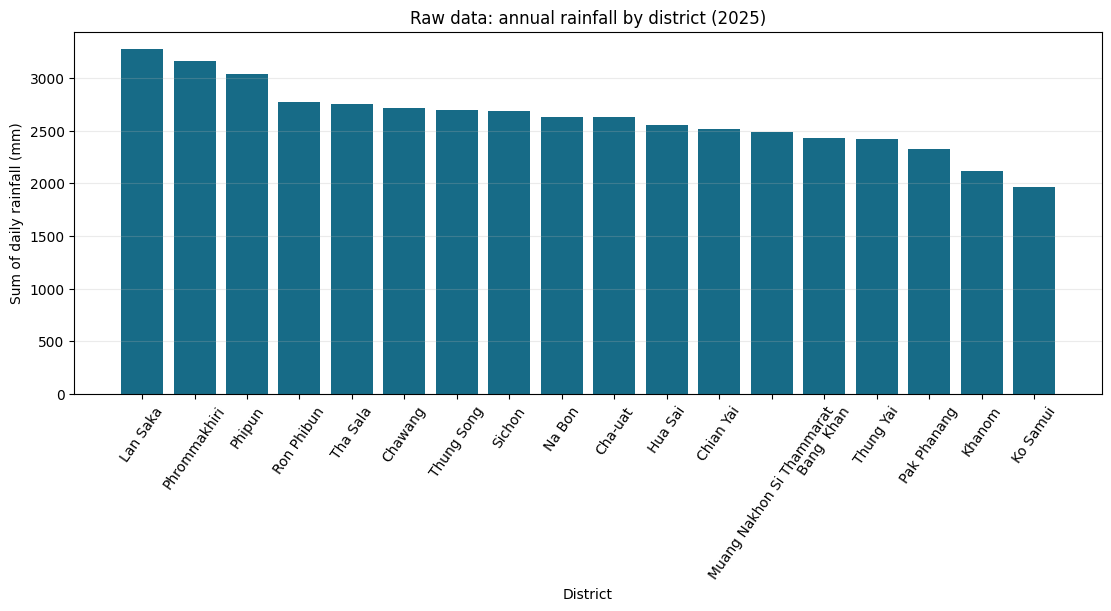

In [3]:
raw_annual_district = raw_for_eda.groupby(
    ['year_for_eda', 'district'], as_index=False
).agg(annual_rain_mm=('rain_mm', 'sum'))
latest_year = int(raw_annual_district['year_for_eda'].max())
latest_districts = raw_annual_district.loc[
    raw_annual_district['year_for_eda'] == latest_year
].sort_values('annual_rain_mm', ascending=False)
fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
ax.bar(latest_districts['district'], latest_districts['annual_rain_mm'], color='#176B87')
ax.set(title=f'Raw data: annual rainfall by district ({latest_year})', xlabel='District', ylabel='Sum of daily rainfall (mm)')
ax.tick_params(axis='x', labelrotation=55)
ax.grid(axis='y', alpha=.25)
display(fig)
plt.close(fig)

## 3. Clean ข้อมูล

จัดช่องว่างชื่อจังหวัด/อำเภอ แปลงวันที่และคอลัมน์ตัวเลข ลบข้อมูลซ้ำ และตัดแถวที่ขาดข้อมูลจำเป็น ค่าฝนติดลบขนาดเล็กมากจากความคลาดเคลื่อนเชิงตัวเลขจะปรับเป็น 0 ส่วน `heavy` ที่หายไปจะคงเป็นค่าว่าง ไม่เดาค่าทดแทน

In [4]:
clean_data = raw_data.copy()
for column in ['province', 'district']:
    clean_data[column] = clean_data[column].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)

numeric_columns = ['district_code', 'rh_pct', 'q_gkg', 'dewpoint_c', 'temp_c', 'rain_mm', 'heavy']
for column in numeric_columns:
    clean_data[column] = pd.to_numeric(clean_data[column], errors='coerce')
clean_data['date'] = pd.to_datetime(clean_data['date'], errors='coerce')

rows_before = len(clean_data)
clean_data = clean_data.drop_duplicates(subset=['district_code', 'date']).copy()
print(f'ลบข้อมูลอำเภอ-วันที่ซ้ำ: {rows_before - len(clean_data)} แถว')

required_columns = ['province', 'district', 'district_code', 'date', 'rh_pct', 'q_gkg', 'dewpoint_c', 'temp_c', 'rain_mm']
invalid_required = clean_data[required_columns].isna().any(axis=1)
if invalid_required.any():
    print(f'ลบแถวที่ข้อมูลหลักขาดหาย/ไม่ถูกต้อง: {int(invalid_required.sum())} แถว')
    clean_data = clean_data.loc[~invalid_required].copy()
else:
    print('ไม่พบข้อมูลหลักที่ขาดหายหรือไม่ถูกต้อง')

if not clean_data['rh_pct'].between(0, 100).all():
    raise ValueError('พบค่า rh_pct นอกช่วง 0–100% กรุณาตรวจสอบข้อมูล')
if (clean_data['rain_mm'] < -1e-4).any():
    raise ValueError('พบปริมาณฝนติดลบเกินค่าคลาดเคลื่อนที่ยอมรับได้')
tiny_negative_rain = clean_data['rain_mm'].between(-1e-4, 0, inclusive='left')
print(f'ปรับค่าฝนติดลบขนาดเล็กเป็น 0: {int(tiny_negative_rain.sum())} ค่า')
clean_data.loc[tiny_negative_rain, 'rain_mm'] = 0.0

invalid_heavy = clean_data['heavy'].notna() & ~clean_data['heavy'].isin([0, 1])
if invalid_heavy.any():
    raise ValueError('พบค่า heavy ที่ไม่ใช่ 0, 1 หรือค่าว่าง')
clean_data['heavy'] = clean_data['heavy'].astype('Int8')
print(f'Clean เสร็จ: {len(clean_data):,} แถว | heavy ที่ไม่มีค่า: {int(clean_data["heavy"].isna().sum())} แถว')

ลบข้อมูลอำเภอ-วันที่ซ้ำ: 0 แถว
ลบแถวที่ข้อมูลหลักขาดหาย/ไม่ถูกต้อง: 2192 แถว
ปรับค่าฝนติดลบขนาดเล็กเป็น 0: 0 ค่า
Clean เสร็จ: 37,264 แถว | heavy ที่ไม่มีค่า: 0 แถว


## 4. Data Prep

เตรียมข้อมูลสำหรับวิเคราะห์แยกจาก Clean: สร้างคอลัมน์ปี เดือน และวันที่เริ่มเดือน จัดชนิดข้อมูล เรียงตามอำเภอและวันที่ และกำหนดลำดับคอลัมน์

In [5]:
data_prep = clean_data.copy()
data_prep['district_code'] = data_prep['district_code'].astype('int64')
data_prep['year'] = data_prep['date'].dt.year.astype('int64')
data_prep['month'] = data_prep['date'].dt.month.astype('int64')
data_prep['month_start'] = data_prep['date'].dt.to_period('M').dt.to_timestamp()
prepared_columns = [
    'province', 'district', 'district_code', 'date', 'year', 'month', 'month_start',
    'rh_pct', 'q_gkg', 'dewpoint_c', 'temp_c', 'rain_mm', 'heavy',
]
data_prep = data_prep[prepared_columns].sort_values(
    ['district_code', 'date']
).reset_index(drop=True)

if data_prep.duplicated(['district_code', 'date']).any():
    raise ValueError('พบข้อมูลซ้ำของอำเภอและวันที่ใน Data Prep')
if data_prep[['province', 'district', 'date', 'rh_pct', 'q_gkg', 'dewpoint_c', 'temp_c', 'rain_mm']].isna().any().any():
    raise ValueError('พบค่าว่างในข้อมูลหลักหลัง Data Prep')

print('ขนาดตาราง Data Prep:', data_prep.shape)
print('ช่วงปี:', int(data_prep['year'].min()), 'ถึง', int(data_prep['year'].max()))
print('จำนวนอำเภอ:', data_prep['district'].nunique())
display(data_prep.head())

ขนาดตาราง Data Prep: (37264, 13)
ช่วงปี: 2020 ถึง 2025
จำนวนอำเภอ: 17


,province,district,district_code,date,year,month,month_start,rh_pct,q_gkg,dewpoint_c,temp_c,rain_mm,heavy
0,นครศรีธรรมราช,Bang Khan,26738,2020-01-01,2020,1,2020-01-01,76.31,15.95,21.44,25.93,0.0,0
1,นครศรีธรรมราช,Bang Khan,26738,2020-01-02,2020,1,2020-01-01,77.48,16.28,21.77,26.02,0.0,0
2,นครศรีธรรมราช,Bang Khan,26738,2020-01-03,2020,1,2020-01-01,81.57,16.95,22.41,25.80,0.0,0
3,นครศรีธรรมราช,Bang Khan,26738,2020-01-04,2020,1,2020-01-01,75.65,16.31,21.76,26.41,0.0,0
4,นครศรีธรรมราช,Bang Khan,26738,2020-01-05,2020,1,2020-01-01,75.34,15.82,21.27,25.98,0.0,0


## 5. EDA หลัง Clean และ Data Prep

แสดงกราฟแนวโน้มรายเดือนจาก `data_prep` หลัง Clean และ Data Prep แล้ว และสัดส่วนวันที่มีฝนหนักจากค่า `heavy` ที่มีข้อมูล

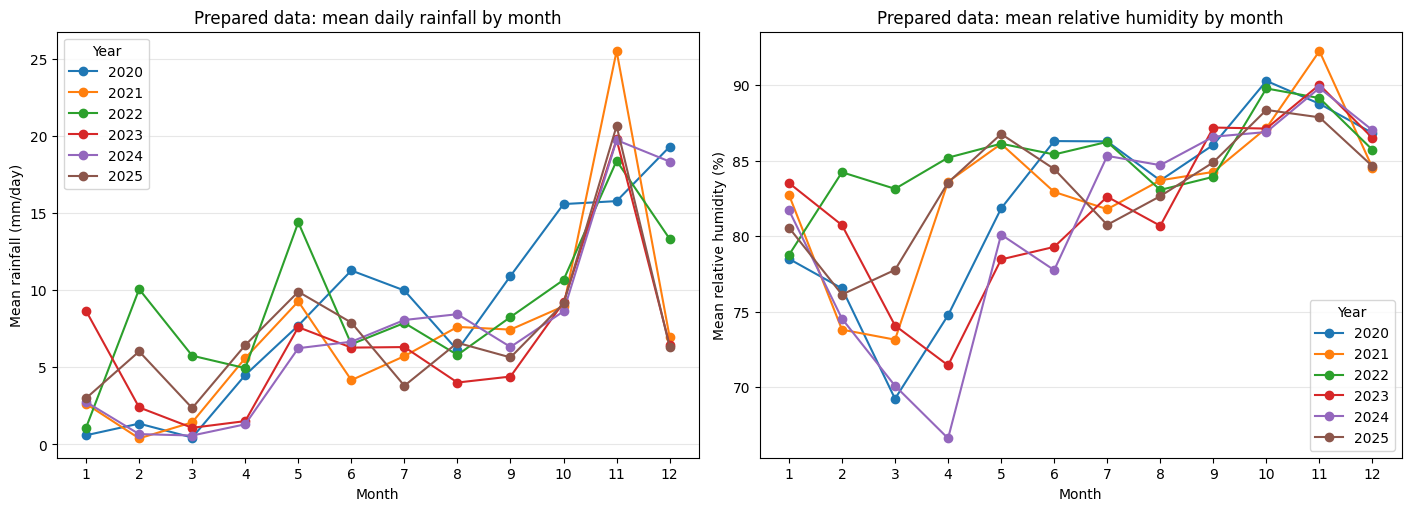

,year,mean_rain_mm,mean_rh_pct,heavy_days,valid_heavy_records,heavy_pct
0,2020,8.64,82.44,263,6222,4.23
1,2021,7.15,83.05,261,6205,4.21
2,2022,8.90,85.06,308,6205,4.96
3,2023,6.48,81.81,204,6205,3.29
4,2024,7.33,80.97,250,6222,4.02
5,2025,7.29,83.24,234,6205,3.77


In [6]:
prepared_monthly = data_prep.groupby(['year', 'month'], as_index=False).agg(
    mean_rain_mm=('rain_mm', 'mean'),
    mean_rh_pct=('rh_pct', 'mean'),
    heavy_days=('heavy', 'sum'),
    valid_heavy_records=('heavy', 'count'),
)
prepared_monthly['heavy_pct'] = (
    prepared_monthly['heavy_days'] / prepared_monthly['valid_heavy_records'] * 100
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for year in sorted(prepared_monthly['year'].unique()):
    subset = prepared_monthly.loc[prepared_monthly['year'] == year]
    axes[0].plot(subset['month'], subset['mean_rain_mm'], marker='o', label=str(year))
    axes[1].plot(subset['month'], subset['mean_rh_pct'], marker='o', label=str(year))
axes[0].set(title='Prepared data: mean daily rainfall by month', xlabel='Month', ylabel='Mean rainfall (mm/day)', xticks=range(1, 13))
axes[1].set(title='Prepared data: mean relative humidity by month', xlabel='Month', ylabel='Mean relative humidity (%)', xticks=range(1, 13))
for ax in axes:
    ax.grid(axis='y', alpha=.3)
    ax.legend(title='Year')
display(fig)
plt.close(fig)

annual = data_prep.groupby('year', as_index=False).agg(
    mean_rain_mm=('rain_mm', 'mean'),
    mean_rh_pct=('rh_pct', 'mean'),
    heavy_days=('heavy', 'sum'),
    valid_heavy_records=('heavy', 'count'),
)
annual['heavy_pct'] = annual['heavy_days'] / annual['valid_heavy_records'] * 100
display(annual.round(2))

## 6. Save CSV

บันทึก `data_prep` หลัง Clean และ Data Prep ลงใน `clean_data_set/` แยกเป็นเซลล์สุดท้าย

In [7]:
output_dir = root / 'clean_data_set'
output_dir.mkdir(parents=True, exist_ok=True)
csv_path = output_dir / 'NST_district_daily_humidity_2020_2025_clean.csv'
data_prep.to_csv(csv_path, index=False, encoding='utf-8-sig', float_format='%.6f', date_format='%Y-%m-%d')
print(f'บันทึก CSV แล้ว: {csv_path}')
print(f'{len(data_prep):,} แถว | {data_prep["district"].nunique()} อำเภอ | ปี {years}')

บันทึก CSV แล้ว: c:\Users\sitti\OneDrive\Desktop\nahh ahhh ver nine edit - Copy\nahh ahhh\clean_data_set\NST_district_daily_humidity_2020_2025_clean.csv
37,264 แถว | 17 อำเภอ | ปี [2020, 2021, 2022, 2023, 2024, 2025]
